In [28]:
%load_ext autoreload
%autoreload 2

import torch
import matplotlib.pyplot as plt
from pathlib import Path

from MuZero.networks import MuZeroNetwork
from MuZero.train import train_muzero
from MuZero.evaluate import evaluate_model

from hidden_hand import HiddenHandEnv
from hidden_hand.bots import make_bot

from MuZero.encoder import encode_observation
from MuZero.mcts import run_mcts


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Load model if it exists already

In [23]:
# Location of your saved model
model_path = Path("checkpoints/muzero_rule_aware_100iter_2000buffer.pth")

# Check that the file exists
print("Current directory:", Path.cwd())
print("Model exists:", model_path.exists())

# Create the neural network
loaded_model = MuZeroNetwork()

# Load the trained weights
loaded_model.load_state_dict(
    torch.load(
        model_path,
        map_location="cpu",
        weights_only=True
    )
)

loaded_model.eval()

evaluation_model = loaded_model

print("Model loaded successfully!")

Current directory: C:\Users\polar\PycharmProjects\learning-skynet\MuZero
Model exists: True
Model loaded successfully!


Untrained model performance

In [2]:
untrained_model = MuZeroNetwork()

evaluate_model(untrained_model, num_games=2000)

Games played: 2000
MuZero wins: 864
MuZero losses: 1117
Ties: 19
Win rate: 0.432
Average score: 25.6885


Train model to see improvment

In [41]:
trained_model, policy_history, value_history, reward_history, validation_history = train_muzero(
    num_iterations=100,
    games_per_iteration=20,
    training_steps=20,
    num_validation_games=10
)

evaluation_model = trained_model
evaluation_model.eval()

Iteration: 1
Games stored: 20
Average training loss: 158.29483489990236
Validation loss: 122.08193715413411
-----------------------------
Iteration: 2
Games stored: 40
Average training loss: 200.0738311767578
Validation loss: 107.66524887084961
-----------------------------
Iteration: 3
Games stored: 60
Average training loss: 222.76327743530274
Validation loss: 73.20129833221435
-----------------------------
Iteration: 4
Games stored: 80
Average training loss: 212.24276609420775
Validation loss: 40.465112908681235
-----------------------------
Iteration: 5
Games stored: 100
Average training loss: 168.68776264190674
Validation loss: 63.755557759602866
-----------------------------
Iteration: 6
Games stored: 120
Average training loss: 137.5137234687805
Validation loss: 86.83163715998332
-----------------------------
Iteration: 7
Games stored: 140
Average training loss: 112.22153577804565
Validation loss: 113.48639227549235
-----------------------------
Iteration: 8
Games stored: 160
Aver

MuZeroNetwork(
  (representation): RepresentationNetwork(
    (layers): Sequential(
      (0): Linear(in_features=303, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): ReLU()
    )
  )
  (dynamics): DynamicsNetwork(
    (layers): Sequential(
      (0): Linear(in_features=135, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): ReLU()
    )
    (reward_head): Linear(in_features=128, out_features=2, bias=True)
  )
  (prediction): PredictionNetwork(
    (layers): Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): ReLU()
    )
    (policy_head): Linear(in_features=128, out_features=7, bias=True)
    (value_head): Linear(in_features=128, out_features=2, bias=True)
  )
)

Optional model save.

In [22]:
# Create a directory for saved models
Path("checkpoints").mkdir(exist_ok=True)

# Save the model from this experiment
torch.save(
    trained_model.state_dict(),
    "checkpoints/muzero_rule_aware_100iter_2000buffer.pth"
)

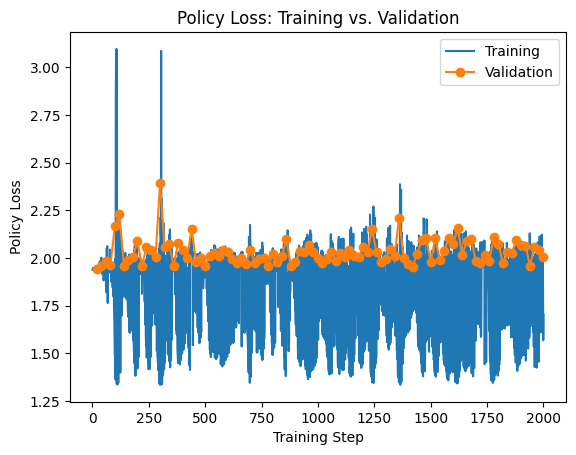

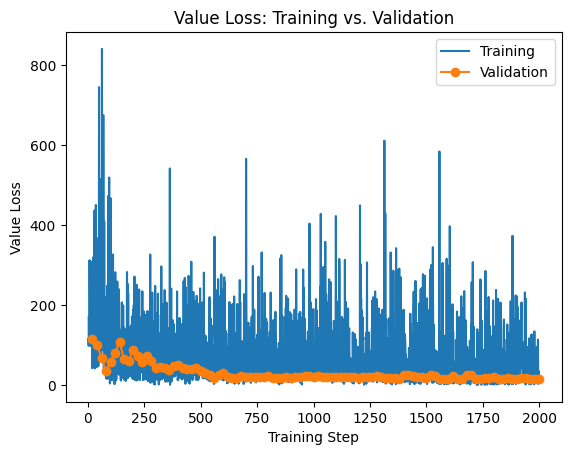

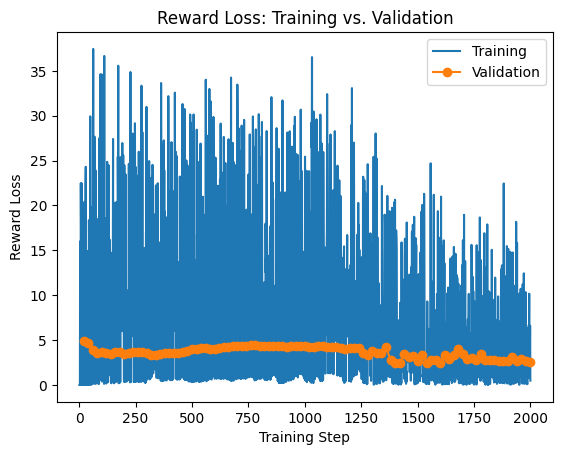

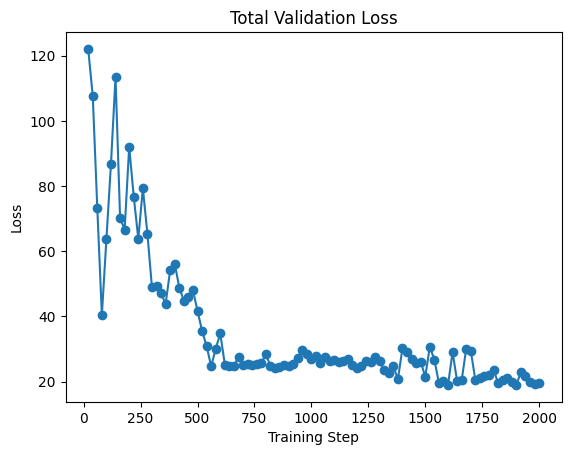

In [42]:
# Validation is measured once per iteration
validation_steps = [
    result["step"]
    for result in validation_history
]

# Graph policy, value, and reward losses
for name, training_history in [
    ("policy", policy_history),
    ("value", value_history),
    ("reward", reward_history)
]:

    validation_values = [
        result[name]
        for result in validation_history
    ]

    plt.figure()

    # Training loss measured after every training step
    plt.plot(
        range(1, len(training_history) + 1),
        training_history,
        label="Training"
    )

    # Validation loss measured after every iteration
    plt.plot(
        validation_steps,
        validation_values,
        label="Validation",
        marker="o"
    )

    plt.xlabel("Training Step")
    plt.ylabel(name.capitalize() + " Loss")
    plt.title(name.capitalize() + " Loss: Training vs. Validation")

    plt.legend()
    plt.show()


# Graph total validation loss
plt.figure()

plt.plot(
    validation_steps,
    [result["total"] for result in validation_history],
    marker="o"
)

plt.title("Total Validation Loss")
plt.xlabel("Training Step")
plt.ylabel("Loss")

plt.show()

Re-evaluate

In [13]:
evaluate_model(trained_model, num_games=2000)

Games played: 2000
MuZero wins: 738
MuZero losses: 1262
Ties: 0
Win rate: 0.369
Average score: 32.747


Training with different number of iterations.

In [5]:
iterations = [10, 20, 30, 40, 50, 100]

eval_results = []

for iteration in iterations:

    print(f"\nTraining MuZero for {iteration} iterations")

    (
        experiment_model,
        experiment_policy_history,
        experiment_value_history,
        experiment_reward_history,
        experiment_validation_history
    ) = train_muzero(
        num_iterations=iteration,
        games_per_iteration=20,
        training_steps=20,
        num_validation_games=10
    )

    results = evaluate_model(
        experiment_model,
        num_games=2000
    )

    results["iteration"] = iteration

    eval_results.append(results)

print(eval_results)


Training MuZero for 10 iterations
Iteration: 1
Games stored: 20
Average training loss: 102.89882583618164
Validation loss: 37.13929433822632
-----------------------------
Iteration: 2
Games stored: 40
Average training loss: 218.22488327026366
Validation loss: 29.077066516876222
-----------------------------
Iteration: 3
Games stored: 60
Average training loss: 87.67893991470336
Validation loss: 32.448305416107175
-----------------------------
Iteration: 4
Games stored: 80
Average training loss: 170.17008504867553
Validation loss: 31.87358388900757
-----------------------------
Iteration: 5
Games stored: 100
Average training loss: 114.81933040618897
Validation loss: 24.019837427139283
-----------------------------
Iteration: 6
Games stored: 120
Average training loss: 198.98287811279297
Validation loss: 29.11770095825195
-----------------------------
Iteration: 7
Games stored: 140
Average training loss: 152.67593870162963
Validation loss: 39.31720333099365
-----------------------------
I

See results in training results.md

In [10]:
simulation_counts = [16, 32, 64]

simulation_results = []

for simulations in simulation_counts:

    print(f"\nEvaluating with {simulations} simulations")

    results = evaluate_model(
        evaluation_model,
        num_games=2000,
        num_simulations=simulations
    )

    results["simulations"] = simulations

    simulation_results.append(results)


Evaluating with 16 MCTS simulations
Games played: 2000
MuZero wins: 757
MuZero losses: 1243
Ties: 0
Win rate: 0.3785
Average score: 32.5365

Evaluating with 32 MCTS simulations
Games played: 2000
MuZero wins: 738
MuZero losses: 1262
Ties: 0
Win rate: 0.369
Average score: 32.651

Evaluating with 64 MCTS simulations
Games played: 2000
MuZero wins: 749
MuZero losses: 1251
Ties: 0
Win rate: 0.3745
Average score: 32.477
[{'wins': 757, 'losses': 1243, 'ties': 0, 'win_rate': 0.3785, 'average_score': 32.5365, 'simulations': 16}, {'wins': 738, 'losses': 1262, 'ties': 0, 'win_rate': 0.369, 'average_score': 32.651, 'simulations': 32}, {'wins': 749, 'losses': 1251, 'ties': 0, 'win_rate': 0.3745, 'average_score': 32.477, 'simulations': 64}]


Lets graph the results from the different number of iterations

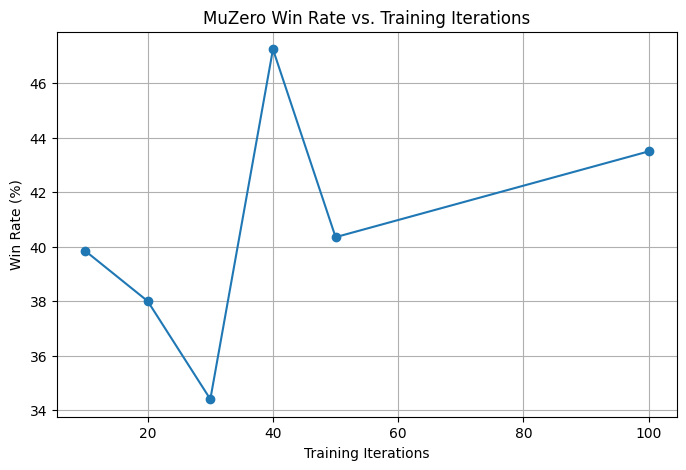

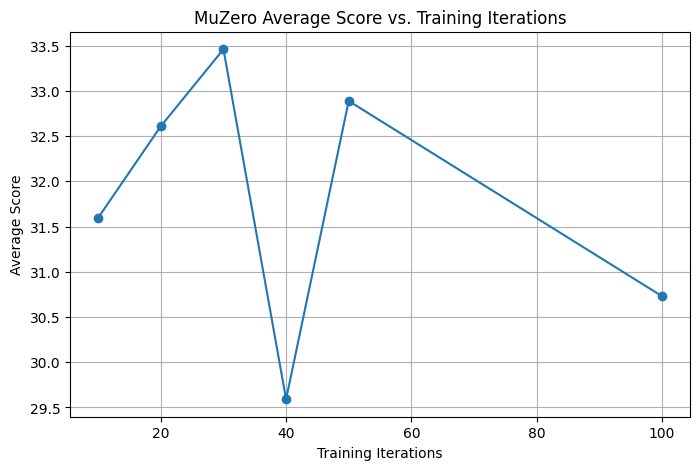

In [11]:
# Extract results
x = [result["iteration"] for result in eval_results]

win_rates = [
    result["win_rate"] * 100
    for result in eval_results
]

average_scores = [
    result["average_score"]
    for result in eval_results
]

# Graph win rate
plt.figure(figsize=(8, 5))

plt.plot(x, win_rates, marker="o")

plt.title("MuZero Win Rate vs. Training Iterations")
plt.xlabel("Training Iterations")
plt.ylabel("Win Rate (%)")
plt.grid(True)
plt.show()

# Graph average score
plt.figure(figsize=(8, 5))

plt.plot(x, average_scores, marker="o")

plt.title("MuZero Average Score vs. Training Iterations")
plt.xlabel("Training Iterations")
plt.ylabel("Average Score")
plt.grid(True)
plt.show()

This defines the function we'll use to evaluate our model against the bots.

In [13]:
def evaluate_against_bot(
    model,
    opponent_name,
    num_games=2000,
    num_simulations=16
):
    wins = 0
    losses = 0
    ties = 0
    total_score = 0

    # Remember the model's original mode
    was_training = model.training
    model.eval()

    try:
        for seed in range(num_games):

            # Create a reproducible game
            env = HiddenHandEnv(seed=seed)
            observation = env.reset()

            # Alternate which player MuZero controls
            muzero_player = seed % 2

            # Create the selected opponent
            opponent = make_bot(
                opponent_name,
                seed=seed + 10000
            )

            while not env.game_over:

                player = env.current_player
                legal_actions = env.legal_actions()

                if player == muzero_player:

                    # MuZero chooses using MCTS
                    encoded_obs = encode_observation(observation)

                    action, root = run_mcts(
                        model=model,
                        encoded_observation=encoded_obs,
                        legal_actions=legal_actions,
                        current_player=player,
                        num_simulations=num_simulations,
                        observation=observation,
                        game_config=env.config
                    )

                else:

                    # Opponent chooses using its own strategy
                    action = opponent.select_action(
                        observation,
                        legal_actions
                    )

                observation, rewards, done, info = env.step(action)

            # Collect final game scores
            muzero_score = env.scores[muzero_player]
            opponent_score = env.scores[1 - muzero_player]

            total_score += muzero_score

            if muzero_score < opponent_score:
                wins += 1

            elif muzero_score > opponent_score:
                losses += 1

            else:
                ties += 1

    finally:
        model.train(was_training)

    return {
        "opponent": opponent_name,
        "games": num_games,
        "wins": wins,
        "losses": losses,
        "ties": ties,
        "win_rate": wins / num_games,
        "average_score": total_score / num_games
    }

Quick Eval Test

In [24]:
print("Evaluation model:", type(evaluation_model).__name__)

results = evaluate_against_bot(
    evaluation_model,
    opponent_name="random",
    num_games=20,
    num_simulations=16
)

print(results)

Evaluation model: MuZeroNetwork
{'opponent': 'random', 'games': 20, 'wins': 13, 'losses': 7, 'ties': 0, 'win_rate': 0.65, 'average_score': 24.2}


Run the comparison

In [44]:
opponents = ["random", "greedy", "tell_reader"]

evaluation_results = []

for opponent_name in opponents:

    results = evaluate_against_bot(
        evaluation_model,
        opponent_name=opponent_name,
        num_games=2000,
        num_simulations=16
    )

    evaluation_results.append(results)

    print(opponent_name, results)

random {'opponent': 'random', 'games': 2000, 'wins': 859, 'losses': 1141, 'ties': 0, 'win_rate': 0.4295, 'average_score': 30.876}
greedy {'opponent': 'greedy', 'games': 2000, 'wins': 951, 'losses': 1049, 'ties': 0, 'win_rate': 0.4755, 'average_score': 29.1805}
tell_reader {'opponent': 'tell_reader', 'games': 2000, 'wins': 486, 'losses': 1514, 'ties': 0, 'win_rate': 0.243, 'average_score': 33.179}


Compare results to the targets

In [45]:
import pandas as pd

# Minimum required win rates
targets = {
    "random": 0.36,
    "greedy": 0.45,
    "tell_reader": 0.20
}

rows = []

for result in evaluation_results:

    opponent = result["opponent"]
    win_rate = result["win_rate"]
    minimum = targets[opponent]

    rows.append({
        "Opponent": opponent,
        "Win Rate (%)": round(win_rate * 100, 2),
        "Minimum (%)": minimum * 100,
        "Average Score": round(result["average_score"], 2),
        "Status": "PASS" if win_rate >= minimum else "FAIL"
    })

results_table = pd.DataFrame(rows)

display(results_table)

,Opponent,Win Rate (%),Minimum (%),Average Score,Status
0,random,42.95,36.0,30.88,PASS
1,greedy,47.55,45.0,29.18,PASS
2,tell_reader,24.30,20.0,33.18,PASS


Graph results for expected values

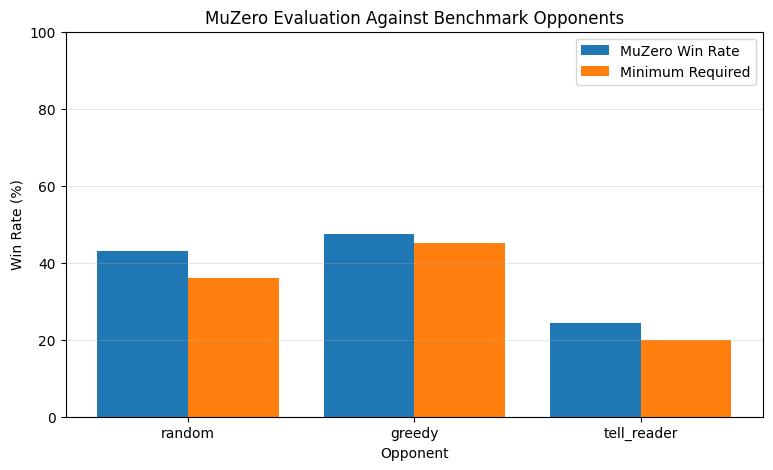

In [46]:
import matplotlib.pyplot as plt

opponent_names = [
    result["opponent"]
    for result in evaluation_results
]

win_rates = [
    result["win_rate"] * 100
    for result in evaluation_results
]

minimum_rates = [
    targets[name] * 100
    for name in opponent_names
]

plt.figure(figsize=(9, 5))

x = range(len(opponent_names))

plt.bar(
    [i - 0.2 for i in x],
    win_rates,
    width=0.4,
    label="MuZero Win Rate"
)

plt.bar(
    [i + 0.2 for i in x],
    minimum_rates,
    width=0.4,
    label="Minimum Required"
)

plt.xticks(x, opponent_names)
plt.ylabel("Win Rate (%)")
plt.xlabel("Opponent")
plt.title("MuZero Evaluation Against Benchmark Opponents")
plt.ylim(0, 100)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

Lets try to diagnose why greedy beats us.

In [48]:
env = HiddenHandEnv(seed=42)
observation = env.reset()

action, root = run_mcts(
    model=evaluation_model,
    encoded_observation=encode_observation(observation),
    legal_actions=env.legal_actions(),
    current_player=env.current_player,
    num_simulations=64,
    observation=observation,
    game_config=env.config
)

action_names = {
    0: "KEEP",
    1: "PEEK",
    2: "TRADE(0)",
    3: "TRADE(1)",
    4: "TRADE(2)",
    5: "TRADE(3)",
    6: "CALL"
}

print("Chosen action:", action_names[action])
print()

for action_id, child in root.children.items():

    # Average future value for the current player
    future_value = child.value(root.player)

    # Predicted immediate reward
    immediate_reward = 0.0

    if child.reward is not None:
        immediate_reward = child.reward[root.player]

    # Estimated action value
    estimated_value = immediate_reward + future_value

    print(
        action_names[action_id],
        "| Visits:", child.visit_count,
        "| Prior:", round(child.prior, 3),
        "| Estimated value:", round(estimated_value, 3)
    )

Chosen action: TRADE(2)

KEEP | Visits: 1 | Prior: 0.117 | Estimated value: -19.064
PEEK | Visits: 1 | Prior: 0.146 | Estimated value: -18.669
TRADE(0) | Visits: 1 | Prior: 0.177 | Estimated value: -18.563
TRADE(1) | Visits: 1 | Prior: 0.17 | Estimated value: -18.442
TRADE(2) | Visits: 59 | Prior: 0.177 | Estimated value: -16.072
TRADE(3) | Visits: 1 | Prior: 0.213 | Estimated value: -18.378


In [49]:
print("Action prediction breakdown")
print("---------------------------")

for action_id, child in root.children.items():

    if child.hidden_state is None:
        continue

    # Predicted immediate reward from taking the action
    immediate_reward = child.reward[root.player]

    # Estimated future reward after the action
    future_value = child.value(root.player)

    total_value = immediate_reward + future_value

    print(
        action_names[action_id],
        "| Immediate reward:", round(immediate_reward, 3),
        "| Future value:", round(future_value, 3),
        "| Total:", round(total_value, 3)
    )

Action prediction breakdown
---------------------------
KEEP | Immediate reward: 2.925 | Future value: -21.989 | Total: -19.064
PEEK | Immediate reward: 1.642 | Future value: -20.311 | Total: -18.669
TRADE(0) | Immediate reward: 1.742 | Future value: -20.305 | Total: -18.563
TRADE(1) | Immediate reward: 0.647 | Future value: -19.089 | Total: -18.442
TRADE(2) | Immediate reward: 0.165 | Future value: -16.237 | Total: -16.072
TRADE(3) | Immediate reward: 0.792 | Future value: -19.17 | Total: -18.378


In [27]:
from MuZero.self_play import play_game

# Generate a game using the trained model
game_history = play_game(evaluation_model, seed=42)

evaluation_model.eval()

with torch.no_grad():

    for turn_number, turn in enumerate(game_history):

        observation = turn["observation"].unsqueeze(0)

        # Get the current hidden representation
        hidden_state, policy, value = evaluation_model.initial_inference(
            observation
        )

        # Predict reward after the recorded action
        action = torch.tensor([turn["action"]])

        next_state, predicted_reward, next_policy, next_value = (
            evaluation_model.recurrent_inference(
                hidden_state,
                action
            )
        )

        actual_reward = turn["rewards"]

        print(
            "Turn:", turn_number + 1,
            "| Action:", turn["action"],
            "| Predicted:", predicted_reward[0].tolist(),
            "| Actual:", actual_reward
        )

Turn: 1 | Action: 4 | Predicted: [0.4908597469329834, 0.2749106287956238] | Actual: {'player_0': 0.0, 'player_1': 0.0}
Turn: 2 | Action: 4 | Predicted: [0.6163021326065063, 0.41279977560043335] | Actual: {'player_0': 0.0, 'player_1': 0.0}
Turn: 3 | Action: 4 | Predicted: [0.8861091136932373, 1.0053057670593262] | Actual: {'player_0': 0.0, 'player_1': 0.0}
Turn: 4 | Action: 4 | Predicted: [-0.7576569318771362, -0.5255966782569885] | Actual: {'player_0': 0.0, 'player_1': 0.0}
Turn: 5 | Action: 6 | Predicted: [-26.39004898071289, -24.62106704711914] | Actual: {'player_0': -16.0, 'player_1': -7.0}


In [50]:
def measure_reward_errors(model, num_games=20):

    terminal_errors = []
    nonterminal_errors = []

    model.eval()

    with torch.no_grad():

        for seed in range(num_games):

            game = play_game(model, seed=seed)

            for index, turn in enumerate(game):

                observation = turn["observation"].unsqueeze(0)

                hidden_state, _, _ = model.initial_inference(
                    observation
                )

                action = torch.tensor([turn["action"]])

                _, predicted_reward, _, _ = model.recurrent_inference(
                    hidden_state,
                    action
                )

                actual_reward = torch.tensor([
                    turn["rewards"]["player_0"],
                    turn["rewards"]["player_1"]
                ])

                error = (
                    predicted_reward[0] - actual_reward
                ).abs().mean().item()

                if index == len(game) - 1:
                    terminal_errors.append(error)
                else:
                    nonterminal_errors.append(error)

    print(
        "Average terminal reward error:",
        sum(terminal_errors) / len(terminal_errors)
    )

    print(
        "Average nonterminal reward error:",
        sum(nonterminal_errors) / len(nonterminal_errors)
    )

In [51]:
measure_reward_errors(
    trained_model,
    num_games=20
)

Average terminal reward error: 9.022398233413696
Average nonterminal reward error: 0.7054375045001506


Test the value network directly

In [47]:
from MuZero.trainer import future_returns


def measure_value_errors(model, num_games=20):

    errors = []

    model.eval()

    with torch.no_grad():

        for seed in range(num_games):

            game = play_game(model, seed=seed)

            for turn_index, turn in enumerate(game):

                # Actual encoded observation
                observation = turn["observation"].unsqueeze(0)

                # Predict future values for both players
                hidden_state, policy, predicted_value = (
                    model.initial_inference(observation)
                )

                # Calculate the actual future returns
                actual_value = torch.tensor(
                    future_returns(game, turn_index),
                    dtype=torch.float32
                )

                # Average error across both players
                error = (
                    predicted_value[0] - actual_value
                ).abs().mean().item()

                errors.append(error)

    print(
        "Average value prediction error:",
        sum(errors) / len(errors)
    )

In [52]:
measure_value_errors(
    evaluation_model,
    num_games=20
)

Average value prediction error: 9.031664352416993
